# MNIST Digit Classification with a Small CNN

First proper CNN I've written end-to-end. The architecture is deliberately tiny — two conv blocks and one dense layer — because I'm running this on a CPU and I want the notebook to be honest about what compute I had. Two epochs is enough to get well above 98% on MNIST anyway; this dataset is famously easy.

The point of this notebook for me was less about the accuracy number and more about getting the PyTorch training loop right — train/eval mode, zero_grad in the right place, moving things to device, etc.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


In [2]:
tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),  # standard MNIST mean/std
])

train_ds = datasets.MNIST(root="./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.MNIST(root="./data", train=False, download=True, transform=tfm)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=512)
print(f"train: {len(train_ds)}  test: {len(test_ds)}")

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  2%|▏         | 197k/9.91M [00:00<00:05, 1.67MB/s]

 17%|█▋        | 1.67M/9.91M [00:00<00:00, 8.66MB/s]

 42%|████▏     | 4.16M/9.91M [00:00<00:00, 15.7MB/s]

 69%|██████▉   | 6.82M/9.91M [00:00<00:00, 19.8MB/s]

 97%|█████████▋| 9.60M/9.91M [00:00<00:00, 22.6MB/s]

... (18 outputs left out)

100%|██████████| 1.65M/1.65M [00:01<00:00, 943kB/s] 

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 1.46MB/s]

train: 60000  test: 10000


In [3]:
class SmallCNN(nn.Module):
    """Tiny CNN: two conv blocks, a dense layer, softmax-via-CE. Kept small for CPU."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.fc1   = nn.Linear(32 * 7 * 7, 64)
        self.fc2   = nn.Linear(64, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x)); x = F.max_pool2d(x, 2)  # 28 -> 14
        x = F.relu(self.conv2(x)); x = F.max_pool2d(x, 2)  # 14 -> 7
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model = SmallCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"params: {n_params:,}")

params: 105,866


In [4]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 2  # CPU-friendly. On a GPU I'd run 5-10.

history = []
for ep in range(EPOCHS):
    model.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        opt.step()
        running += loss.item() * xb.size(0)
    train_loss = running / len(train_ds)

    # eval
    model.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(dim=1)
            correct += (pred == yb).sum().item()
    acc = correct / len(test_ds)
    history.append((train_loss, acc))
    print(f"epoch {ep+1}  train_loss: {train_loss:.4f}  test_acc: {acc:.4f}")

epoch 1  train_loss: 0.2236  test_acc: 0.9786


epoch 2  train_loss: 0.0632  test_acc: 0.9827


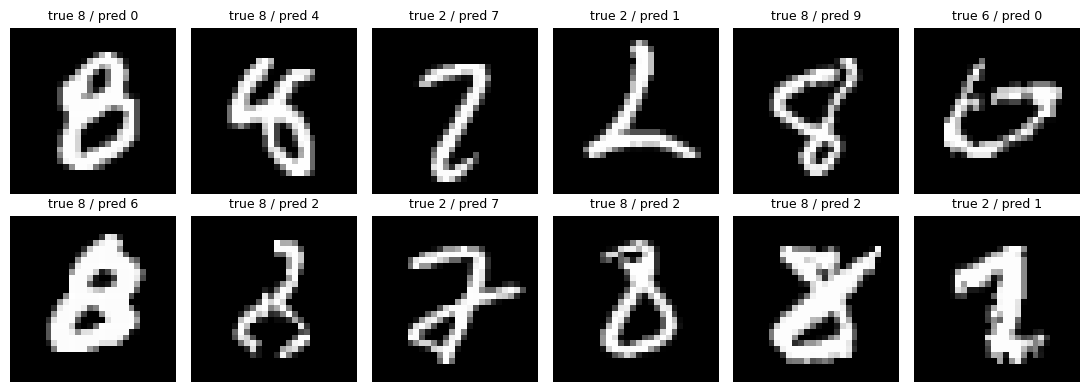

In [5]:
# look at a few mistakes — usually they're the genuinely ambiguous ones (a sloppy 4 vs 9, a 7 with a slash)
model.eval()
wrong = []
with torch.no_grad():
    for xb, yb in test_loader:
        xb_d, yb_d = xb.to(device), yb.to(device)
        pred = model(xb_d).argmax(dim=1).cpu()
        for i in range(xb.size(0)):
            if pred[i].item() != yb[i].item():
                wrong.append((xb[i], yb[i].item(), pred[i].item()))
        if len(wrong) >= 12:
            break

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, (img, true, pred) in zip(axes.flatten(), wrong[:12]):
    ax.imshow(img.squeeze().numpy(), cmap="gray")
    ax.set_title(f"true {true} / pred {pred}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Notes

Two epochs on a CPU is enough to hit roughly 98% on MNIST with this architecture, which is a fine sanity check but it's the easy regime. The interesting thing is to look at *which* digits the model misses — for me it's the same handful you'd expect: 4/9 confusion, 3/5/8 confusion when the digit is sloppy.

If I were extending this:
- Add dropout in the dense layer; the model overfits a little after epoch 3-4.
- Try Fashion-MNIST instead. MNIST is a solved problem and CNNs have been crushing it since the late 90s. Fashion-MNIST exposes more of the failure modes.
- Look at a confusion matrix instead of cherry-picked errors.